## **一、本周要回答什么：从图像重建走向随机生成**

### **1. 学习目标与阅读顺序**

第一周的 DDPM 从噪声反复去噪，学习一个生成过程。这一周学习 **变分自编码器**（Variational Autoencoder，VAE）：先用一个低维随机变量描述图像，再学习如何由这个变量生成图像。

你最终需要回答：为什么编码器输出两个向量？为什么训练时需要随机采样？为什么既有重建项又有 KL？生成时没有输入图像，潜变量从哪里来？这些问题直接关系到下一阶段的潜空间扩散。

建议分四次学习：先读第一至三章理解系统；再读第四至六章推导；第七至十章连接代码与真实实验；最后完成第十一、十二章的迁移与自测。学习约 8–12 小时，自动训练与采样合计最多约 30 分钟。

本 Notebook 是完整教学参考，来源标为 `notebook_reference`。`src` 内 VAE 和 DDPM 核心仍由你完成，没有隐藏 fallback。教学运行通过、个人代码通过、你理解通过是三件事。

### **2. 一个具体动机：能压缩，为什么还不一定能生成？**

普通自编码器 AE 有编码器 $E$ 和解码器 $D$，训练 $D(E(x))$ 接近原图 $x$。编码器可以把训练图像安排在潜空间任意位置；低重建误差并没有规定“随机抽一个坐标应该落在哪里”。如果只见过的坐标附近能解码，随意输入随机数可能得到奇怪图像。

VAE 把编码结果改成 **概率分布**，并引入一个方便采样的先验。重建项要求坐标仍携带图像信息，KL 约束避免这些分布任意远离先验。但这不是“加 KL 就必然生成好图”的保证：模型容量、优化、似然假设与信息约束都影响结果。

不要把“潜变量第 1 维表示笔画粗细”当作默认事实；没有额外条件时，维度通常混合多种因素。

### **3. 本周环境与执行边界**

首个代码单元定位真实项目根，使用已锁定的项目依赖；不注册全局 kernel。原始 MNIST 在 `data/`，Checkpoint 与 HTML 在 `artifacts/`，必要图像在 `reports/stage1/figures/week2/`。重跑将执行本周实验并更新本周输出，不重跑第一周。

In [9]:
import copy
import json
import math
import os
import subprocess
import sys
import time
from pathlib import Path

import torch

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
os.chdir(ROOT)
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from torch.utils.data import TensorDataset

from minigen.data.mnist import prepare_mnist
from minigen.data.stateful import StatefulBatchStream
from minigen.models.tiny_vae import TinyVAE
from minigen.training.denoising import seed_all
from minigen.training.vae import VAEConfig, evaluate_vae, reconstruction_loss, train_vae

plt.rcParams.update({"figure.dpi": 110, "axes.grid": False})
torch.set_num_threads(2)
DEVICE = "mps" if torch.backends.mps.is_available() else "cpu"
RUN = ROOT / "artifacts/runs/s1_week2"
FIG = ROOT / "reports/stage1/figures/week2"
RUN.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)
print(
    {
        "python": sys.version.split()[0],
        "torch": torch.__version__,
        "device": DEVICE,
        "root": str(ROOT),
        "core_source": "notebook_reference",
        "cloud_cost_yuan": 0,
    }
)

{'python': '3.12.14', 'torch': '2.14.1', 'device': 'mps', 'root': '/Users/lucius/projects/personal/MiniGen', 'core_source': 'notebook_reference', 'cloud_cost_yuan': 0}


## **二、先看完整系统：训练与生成各走哪条路**

### **1. 训练时：输入图像，输出分布，再重建图像**

给一张数字图像 $x$，编码器输出均值 $\mu_\phi(x)$ 和对数方差 $\ell_\phi(x)$。它们描述近似后验 $q_\phi(z\mid x)$。从这个分布采样潜变量 $z$，解码器根据 $z$ 输出图像分布 $p_\theta(x\mid z)$ 的参数。

其中 $\phi$ 是编码器参数，$\theta$ 是解码器参数。编码器帮助训练时推断潜变量，解码器构成生成模型的一部分。VAE 不是“每张图像都存在一个已知正确的潜变量标签”。

训练流：`x → encoder → (mean, log_variance) → z → decoder logits → reconstruction objective + KL`。

生成流：`standard Gaussian noise z → decoder → pixel probabilities → image`。生成不需要编码器；若要重建一张已有图像，才使用编码器。

| 张量 | 本周主模型形状 | 角色 |
| --- | --- | --- |
| 图像 $x$ | `[B,1,28,28]` | 范围 `[0,1]` 的真实灰度图 |
| 隐层 | `[B,128]` | 编码器提取的特征 |
| $\mu,\ell$ | 各 `[B,16]` | 每张图像的一组分布参数 |
| $\epsilon,z$ | 各 `[B,16]` | 独立噪声及采样后的潜变量 |
| logits | `[B,1,28,28]` | 解码器输出，未做 sigmoid |
| loss | 标量 | 图像与维度求和后，对 batch 求平均 |

### **2. 三种“输出图像”不要混淆**

**均值重建**：令 $z=\mu(x)$，消除潜变量采样波动，但它不是完整后验预测的积分。

**随机重建**：从 $q_\phi(z\mid x)$ 采样，体现后验不确定性，再查看解码概率图。

**先验生成**：从 $p(z)$ 采样，与任何输入图像无关。重建很好而先验生成差，可能说明编码分布与先验不匹配。

本笔记的图像网格默认显示解码器 sigmoid 后的 **像素概率或灰度均值**，不是逐像素抽取的二值样本。把概率图与真正的 Bernoulli 采样区分开。

## **三、概率基础：这几个分布分别在说什么**

### **1. 联合分布、先验与边缘似然**

设一张图像展平后 $x\in\mathbb R^{784}$，潜变量 $z\in\mathbb R^d$。生成模型先抽坐标，再画图：

$$p_\theta(x,z)=p(z)p_\theta(x\mid z),\qquad p(z)=\mathcal N(0,I_d)$$

先验 $p(z)$ 是看见图像前对坐标的假设；似然 $p_\theta(x\mid z)$ 表示给定坐标后图像出现的概率或密度。边缘似然要考虑所有可能的坐标：

$$p_\theta(x)=\int p(z)p_\theta(x\mid z)\,\mathrm dz$$

该积分穿过非线性神经网络，一般不能直接精确计算。训练想提高真实图像的似然，却面临积分困难。

### **2. 真实后验与近似后验**

真实后验是“已经看见这张图，哪些坐标更可能产生它”：

$$p_\theta(z\mid x)=\frac{p(z)p_\theta(x\mid z)}{p_\theta(x)}$$

分母正是难算的边缘似然。于是另训练一个易计算、易采样的近似分布 $q_\phi(z\mid x)$。这里 **近似的是后验分布**，不是把真实图像近似成标签。

本周用对角高斯：

$$q_\phi(z\mid x)=\mathcal N\!\left(\mu_\phi(x),\operatorname{diag}(\exp\ell_\phi(x))\right)$$

“对角”是给定 $x$ 后各潜变量坐标条件独立的建模假设。它不表示整个数据集的聚合潜变量也逐维独立。

### **3. 离散例子：积分的困难与编码器的工作**

> 假设潜变量只有 A、B 两种，先验各为 0.5。某张图在 A 下的概率为 0.8，在 B 下为 0.2。那么 $p(x)=0.5\times0.8+0.5\times0.2=0.5$。后验 $p(A\mid x)=0.8$、$p(B\mid x)=0.2$。这里可以穷举两项；连续高维坐标不能这样直接枚举。编码器学的是看图后如何把概率重新分配到合适坐标。

In [10]:
prior = torch.tensor([0.5, 0.5], dtype=torch.float64)
likelihood = torch.tensor([0.8, 0.2], dtype=torch.float64)
evidence = (prior * likelihood).sum()
posterior = prior * likelihood / evidence
print({"p(x)": evidence.item(), "posterior": posterior.tolist()})
assert torch.allclose(posterior, torch.tensor([0.8, 0.2], dtype=torch.float64))

{'p(x)': 0.5, 'posterior': [0.8, 0.2]}


## **四、ELBO：把难算的似然变成可以优化的目标**

### **1. 第一条推导：引入近似分布并使用 Jensen 不等式**

固定一张图像 $x$，假设 $q_\phi$ 在联合密度为正的相关位置也有正密度。高斯后验和高斯先验满足本例所需的支持条件。积分中乘除相同的 $q_\phi$：

$$\log p_\theta(x)=\log\int q_\phi(z\mid x)\frac{p_\theta(x,z)}{q_\phi(z\mid x)}\,\mathrm dz=\log\mathbb E_{q_\phi(z\mid x)}\!\left[\frac{p_\theta(x,z)}{q_\phi(z\mid x)}\right]$$

因为 $\log$ 是凹函数，Jensen 不等式给出“先取对数再平均，不大于先平均再取对数”：

$$\log p_\theta(x)\geq\mathbb E_q[\log p_\theta(x,z)-\log q_\phi(z\mid x)]\equiv\mathcal L(x;\theta,\phi)$$

右侧叫 **证据下界**（Evidence Lower Bound，ELBO）；这里“证据”指边缘似然。代入联合分解：

$$\mathcal L=\mathbb E_q[\log p_\theta(x\mid z)]+\mathbb E_q[\log p(z)-\log q_\phi(z\mid x)]$$

根据 $D_{\mathrm{KL}}(q\Vert p)=\mathbb E_q[\log q-\log p]$：

$$\mathcal L=\mathbb E_q[\log p_\theta(x\mid z)]-D_{\mathrm{KL}}(q_\phi(z\mid x)\Vert p(z))$$

第一项鼓励坐标能解释图像；第二项限制编码后验偏离先验。它们共同定义优化目标，不是随意拼接两个看起来有用的指标。

### **2. 第二条推导：下界与真实似然究竟差多少**

从真实后验的定义出发，展开后验之间的 KL：

$$D_{\mathrm{KL}}(q_\phi(z\mid x)\Vert p_\theta(z\mid x))=\mathbb E_q[\log q_\phi(z\mid x)-\log p_\theta(x,z)+\log p_\theta(x)]$$

$\log p_\theta(x)$ 与积分变量 $z$ 无关，提到期望外，得到：

$$\log p_\theta(x)=\mathcal L(x;\theta,\phi)+D_{\mathrm{KL}}(q_\phi(z\mid x)\Vert p_\theta(z\mid x))$$

KL 非负，所以 ELBO 是下界；当 $q_\phi$ 等于真实后验（几乎处处）时取等号。注意这里的 KL 是 **近似后验对真实后验**，而损失里的 KL 是 **近似后验对先验**。前者解释下界差距，后者是可计算的训练项，不能混为一项。

### **3. 数值检查：下界不是另一种似然记号**

> 沿用上一章两状态例子，取近似后验 $q=(0.6,0.4)$。计算 ELBO，并加上 $D_{\mathrm{KL}}(q\Vert p(z\mid x))$，应恰好得到 $\log0.5$。如果取 $q=(0.8,0.2)$，后验 KL 变成零，下界与对数似然相等。

In [11]:
q = torch.tensor([0.6, 0.4], dtype=torch.float64)
elbo = (q * (prior.log() + likelihood.log() - q.log())).sum()
gap = (q * (q.log() - posterior.log())).sum()
print({"log_evidence": evidence.log().item(), "elbo": elbo.item(), "gap": gap.item()})
torch.testing.assert_close(elbo + gap, evidence.log())
assert gap > 0 and elbo < evidence.log()

{'log_evidence': -0.6931471805599453, 'elbo': -0.7977968093128548, 'gap': 0.10464962875290951}


### **4. 从最大化下界到最小化损失**

优化器通常最小化标量，故取负号：

$$J=\mathbb E_q[-\log p_\theta(x\mid z)]+D_{\mathrm{KL}}(q_\phi(z\mid x)\Vert p(z))$$

期望项用一次或多次后验采样近似。本周训练每图一次，验证固定随机噪声，保证对照可复现。一次随机估计不是精确积分。

为了观察约束强弱，实验另设权重 $\beta$：

$$J_\beta=\operatorname{reconstruction}+\beta\operatorname{KL}$$

$\beta=1$ 对应标准负 ELBO 的形式；其他值是改变后的训练目标，不能把所有 $J_\beta$ 都称为相同的似然下界，也不能直接比较加权总目标大小来排名生成质量。这里的 $\beta$ 与 DDPM 的加噪方差 $\beta_t$ 没有同一含义。

## **五、对角高斯 KL：从密度展开到代码归一化**

### **1. 一维推导：每个期望都来自哪里**

设 $q=\mathcal N(\mu,\sigma^2)$，$p=\mathcal N(0,1)$，$\sigma>0$。写出两个对数密度：

$$\log q(z)=-\frac12\log(2\pi)-\log\sigma-\frac{(z-\mu)^2}{2\sigma^2},\qquad\log p(z)=-\frac12\log(2\pi)-\frac{z^2}{2}$$

相减、对 $q$ 取期望，归一化常数抵消：

$$D_{\mathrm{KL}}(q\Vert p)=-\log\sigma-\frac{\mathbb E_q[(z-\mu)^2]}{2\sigma^2}+\frac{\mathbb E_q[z^2]}{2}$$

根据均值和方差定义，$\mathbb E_q[(z-\mu)^2]=\sigma^2$，且 $\mathbb E_q[z^2]=\sigma^2+\mu^2$。代入：

$$D_{\mathrm{KL}}(q\Vert p)=\frac12(\mu^2+\sigma^2-1-\log\sigma^2)$$

由于 $a-1-\log a\geq0$（$a>0$），加上 $\mu^2$ 后非负；在 $\mu=0,\sigma^2=1$ 时为零。

### **2. 多维与 batch：哪里求和，哪里平均**

对角高斯的对数密度是各维相加，故 $d$ 维 KL 也相加。网络输出 $\ell_j=\log\sigma_j^2$，以避免直接输出负方差：

$$D_{\mathrm{KL}}(q\Vert p)=\frac12\sum_{j=1}^{d}(\mu_j^2+\exp\ell_j-1-\ell_j)$$

对 batch 大小 $B$，本项目采用：

$$J_{\mathrm{KL}}=\frac1B\sum_{b=1}^B\frac12\sum_{j=1}^{d}(\mu_{bj}^2+\exp\ell_{bj}-1-\ell_{bj})$$

如果改成对 batch 与潜变量同时平均，KL 就小了 $d$ 倍；如果像素项平均而 KL 求和，二者比例又会改变。因此单独写“KL 权重 1”没有说明完整训练目标。

数值稳定性来自合理初始化、稳定 BCE 和有限值检查；不静默裁剪 log variance 来掩盖训练发散。极端输入导致溢出时应明确诊断。

### **3. 手算例子与独立公式验证**

> 取两维 $\mu=(1,0)$，方差 $(4,1)$。第一维 KL 是 $(1+4-1-\log4)/2=1.3068528$，第二维为零，总 KL 是 1.3068528。若整批复制相同样本，按 batch 平均后的结果不变；若把这两维也平均，结果被错误地减半。

## **六、重参数化：随机采样也能传回梯度**

### **1. 先分清标准差、方差和 log variance**

如果网络输出 $\ell=\log\sigma^2$，那么 $\sigma^2=\exp\ell$，标准差是 $\sigma=\exp(\ell/2)$。采样公式使用 **标准差**：

$$\epsilon\sim\mathcal N(0,I),\qquad z=\mu+\exp(\ell/2)\odot\epsilon$$

$\odot$ 表示逐元素相乘。由独立标准正态噪声的均值零、方差一，可检查 $\mathbb E[z]=\mu$、$\operatorname{Var}(z_j)=\exp\ell_j$。

> 取 $\mu=1$、方差 4，因此 $\ell=\log4$，标准差为 2；噪声为 0.5 时 $z=1+2\times0.5=2$。若误用 $\exp\ell$ 当标准差，将得到 3，采样方差也会错误。

### **2. 为什么换一种写法就能训练**

我们要对 $\mathbb E_{q_\phi(z\mid x)}[f_\theta(z)]$ 求编码器参数的梯度。采样分布本身依赖 $\phi$，不能把抽出的坐标直接当成与参数无关的常数。

重参数化把期望改写为固定噪声分布下的确定变换：

$$\mathbb E_{q_\phi}[f_\theta(z)]=\mathbb E_{\epsilon\sim\mathcal N(0,I)}[f_\theta(\mu_\phi+\exp(\ell_\phi/2)\odot\epsilon)]$$

在可微及允许交换微分与期望的正则条件下，可以对右侧的样本函数做路径梯度。对固定噪声，局部导数是：

$$\frac{\partial z_j}{\partial\mu_j}=1,\qquad\frac{\partial z_j}{\partial\ell_j}=\frac12\exp(\ell_j/2)\epsilon_j$$

再由链式法则传给编码器。不是“所有随机采样都不能求导”：某些库的 `rsample()` 已实现路径梯度；普通 `sample()` 通常不保留这条路径。此处亲手实现是为了看清数学。

### **3. 唯一的教学核心定义**

下面两个函数是本笔记唯一的完整参考核心。输入均为 `[B,d]`，噪声由调用者显式提供；函数不私自重采样。KL 返回标量，固定为维度求和、batch 平均。代码后立即进行独立数值、统计和梯度核验。

In [12]:
def teaching_reparameterize(mean, log_variance, noise):
    if mean.shape != log_variance.shape or mean.shape != noise.shape or mean.ndim != 2:
        raise ValueError("Expected same-shaped [B,d] tensors")
    return mean + torch.exp(0.5 * log_variance) * noise


def teaching_kl(mean, log_variance):
    if mean.shape != log_variance.shape or mean.ndim != 2:
        raise ValueError("Expected same-shaped [B,d] tensors")
    return 0.5 * (mean.square() + log_variance.exp() - 1 - log_variance).sum(1).mean()

In [13]:
mu = torch.tensor([[1.0, 0.0]], dtype=torch.float64, requires_grad=True)
ell = torch.tensor([[math.log(4.0), 0.0]], dtype=torch.float64, requires_grad=True)
eps = torch.tensor([[0.5, -0.25]], dtype=torch.float64)

z = teaching_reparameterize(mu, ell, eps)
torch.testing.assert_close(z, torch.tensor([[2.0, -0.25]], dtype=torch.float64))

kl = teaching_kl(mu, ell)

q_dist = torch.distributions.Independent(torch.distributions.Normal(mu, (0.5 * ell).exp()), 1)
p_dist = torch.distributions.Independent(
    torch.distributions.Normal(torch.zeros_like(mu), torch.ones_like(mu)), 1
)
independent = torch.distributions.kl_divergence(q_dist, p_dist).mean()
torch.testing.assert_close(kl, independent)
assert abs(kl.item() - (4 - math.log(4)) / 2) < 1e-12

z.sum().backward()
torch.testing.assert_close(mu.grad, torch.ones_like(mu))
torch.testing.assert_close(ell.grad, 0.5 * (0.5 * ell.detach()).exp() * eps)
assert torch.autograd.gradcheck(teaching_reparameterize, (mu, ell, eps))
assert torch.autograd.gradcheck(teaching_kl, (mu, ell))
assert teaching_kl(torch.zeros(2, 3), torch.zeros(2, 3)) == 0

noise = torch.randn(100000, 2, dtype=torch.float64, generator=torch.Generator().manual_seed(7))
points = teaching_reparameterize(mu.detach().expand_as(noise), ell.detach().expand_as(noise), noise)
assert (points.mean(0) - mu.detach()[0]).abs().max() < 0.025
assert (points.var(0) - ell.detach().exp()[0]).abs().max() < 0.08

# Statistical KL estimate uses Normal.log_prob rather than the closed-form formula.
mc_kl = (q_dist.log_prob(points) - p_dist.log_prob(points)).mean()
assert abs(mc_kl.item() - kl.item()) < 0.05
math_checks = {
    "kl_closed": kl.item(),
    "kl_distribution": independent.item(),
    "kl_monte_carlo": mc_kl.item(),
    "sample_mean": points.mean(0).tolist(),
    "sample_variance": points.var(0).tolist(),
    "gradcheck": True,
}
print(json.dumps(math_checks, indent=2))

{
  "kl_closed": 1.3068528194400546,
  "kl_distribution": 1.3068528194400546,
  "kl_monte_carlo": 1.279556337592678,
  "sample_mean": [
    0.985003041588823,
    -0.0074455048514778036
  ],
  "sample_variance": [
    3.9670160322355286,
    1.0017771491880203
  ],
  "gradcheck": true
}


数值结果应接近手算值，但经验均值、方差和 Monte Carlo KL 有抽样误差，不应逐项等于理论值。`gradcheck` 用双精度有限差分检查导数；它与“某次训练损失下降”验证的是不同性质。

复制 batch 不应改变 KL；增加不同维度会改变 KL。下面同时检查这些归一化约定与像素重建的缩放。

In [14]:
torch.testing.assert_close(teaching_kl(mu.repeat(3, 1), ell.repeat(3, 1)), kl)
zero_logits = torch.zeros(2, 1, 28, 28)
half_targets = torch.full_like(zero_logits, 0.5)
recon_check = reconstruction_loss(zero_logits, half_targets)
assert abs(recon_check.item() - 784 * math.log(2)) < 0.001
print({"zero_logits_reconstruction": recon_check.item(), "expected": 784 * math.log(2)})

{'zero_logits_reconstruction': 543.427490234375, 'expected': 543.4273895589971}


## **七、网络、数据与目标：把符号接进训练循环**

### **1. 解码器为什么输出 logits**

以真正二值像素 $x_i\in\{0,1\}$ 为例，假设给定 $z$ 后像素独立，像素为 1 的概率为 $\pi_i=\operatorname{sigmoid}(a_i)$：

$$p_\theta(x\mid z)=\prod_{i=1}^{784}\pi_i^{x_i}(1-\pi_i)^{1-x_i}$$

取负对数，把乘积变成加和，就得到二元交叉熵 BCE：

$$-\log p_\theta(x\mid z)=-\sum_i[x_i\log\pi_i+(1-x_i)\log(1-\pi_i)]$$

计算时使用 `binary_cross_entropy_with_logits`，它在 logits 上稳定计算，不先 sigmoid 再取可能接近零的对数。

**本周保留灰度 MNIST**，目标值允许在 `[0,1]`。此时同一个表达式是软目标 BCE，也等于以灰度值为成功概率的二值目标的期望 BCE；它不能直接被解释成连续灰度数据的精确归一化密度。严格的 Bernoulli 似然推导与本项目灰度代理目标在这里明确区分，不报告“精确 log likelihood”。MSE 则对应另一类观测模型及尺度设定，不能不改解释就直接互换。

### **2. 简化网络的职责与限制**

编码器 `784→256→128`，再分成两个输出头；解码器 `d→128→256→784`。激活使用 ReLU，最后一层保留原始 logits。模型接收参考函数，不拥有另一套 KL 或重参数化主体。

展平丢失了显式的空间局部结构，二维向量潜空间也不是 SDXL VAE 的空间特征图。本周选择 MLP 是为了观察分布与训练目标，不是为了获得现代插画质量。

In [15]:
seed_all(0)
shape_model = TinyVAE(16)
shape_x = torch.rand(3, 1, 28, 28)
shape_logits, shape_mean, shape_logvar = shape_model(
    shape_x, torch.zeros(3, 16), reparameterize_fn=teaching_reparameterize
)
print(
    {
        "images": list(shape_x.shape),
        "mean": list(shape_mean.shape),
        "logvar": list(shape_logvar.shape),
        "logits": list(shape_logits.shape),
        "parameters": sum(p.numel() for p in shape_model.parameters()),
    }
)
assert shape_logits.shape == shape_x.shape

{'images': [3, 1, 28, 28], 'mean': [3, 16], 'logvar': [3, 16], 'logits': [3, 1, 28, 28], 'parameters': 474672}


### **3. 沿用第一周划分，显式转换输入范围**

读取相同的固定子集，并核对第一周记录的划分哈希。第一周 loader 输出 `[-1,1]`，本周复制成内存张量后转换为 `[0,1]`，不会更改第一周默认行为。原始来源与文件校验仍由同一个 MNIST 获取工具登记。

标签只用于最后的二维颜色图，不进入编码器、损失或解码器。官方测试集不参与训练或参数选择。本周验证集只承担固定探索对照，没有根据结果再搜索更多权重。

In [16]:
week1_record = json.loads((ROOT / "reports/stage1/week1_results.json").read_text())
train_subset, val_subset, manifest = prepare_mnist(ROOT / "data")
assert week1_record["data"]["split_sha256"] == manifest["split_sha256"]
train_pairs = [train_subset[i] for i in range(len(train_subset))]
val_pairs = [val_subset[i] for i in range(len(val_subset))]
train_x = (torch.stack([pair[0] for pair in train_pairs]) + 1) / 2
val_x = (torch.stack([pair[0] for pair in val_pairs]) + 1) / 2
val_labels = torch.tensor([pair[1] for pair in val_pairs])
train_data = TensorDataset(train_x)
DATA_ID = manifest["split_sha256"] + ":train:gray01:v1"
print(
    {
        "train": len(train_x),
        "validation": len(val_x),
        "range": [train_x.min().item(), train_x.max().item()],
        "split_sha256": manifest["split_sha256"],
        "official_test_used": False,
    }
)

{'train': 10000, 'validation': 1000, 'range': [0.0, 1.0], 'split_sha256': 'caae80b4d0f9cc96b9761366f6d22d0597677efdd880dd86d6837ec3312fbde9', 'official_test_used': False}


## **八、本地短训：先确认能学，再比较约束**

### **1. 固定小批次拟合**

固定 32 张图、潜变量噪声和训练顺序，先跑 100 步，KL 权重设为 0，专门检查重建梯度链是否连接。它不是正式生成模型质量评测，也不能证明先验采样有效。

训练工具记录实际更新、梯度范数、重建、KL、配置和来源；非有限损失直接报错，不产生伪成功结果。正式训练使用独立随机批次和随机潜变量噪声。

拟合验收用相同固定噪声计算前后重建。训练工具另有独立固定随机噪声的 probe，二者不应混用。实际观察中固定监督改善，而换噪声的重建反而可能恶化：这说明可以过拟合一个噪声表，不能把它当作随机后验重建或生成能力。

In [30]:
experiment_start = time.monotonic()
seed_all(0)

fit_model = TinyVAE(16)
fit_noise = torch.randn(32, 16, generator=torch.Generator().manual_seed(100))
fit = train_vae(
    fit_model,
    StatefulBatchStream(
        TensorDataset(train_x[:32]), 32, data_id=DATA_ID + ":fit", seed=0, shuffle=False
    ),
    VAEConfig(
        str(RUN / "fit"),
        beta=0,
        max_steps=100,
        max_seconds=120,
        device=DEVICE,
        core_source="notebook_reference",
    ),
    reparameterize_fn=teaching_reparameterize,
    kl_fn=teaching_kl,
    validation=train_x[:32],
    fixed_noise=fit_noise,
)

with torch.no_grad():
    fit_logits, _, _ = fit_model(
        train_x[:32].to(DEVICE),
        fit_noise.to(DEVICE),
        reparameterize_fn=teaching_reparameterize,
    )
    fit_final_fixed = reconstruction_loss(fit_logits, train_x[:32].to(DEVICE)).item()
fit["fixed_supervision"] = {
    "initial": fit["metrics"][0]["reconstruction"],
    "final": fit_final_fixed,
    "different_noise_probe": fit["final"]["reconstruction"],
}
print({"steps": fit["final_step"], **fit["fixed_supervision"], "stop": fit["stop_reason"]})
assert fit_final_fixed < fit["metrics"][0]["reconstruction"]

fit: step=100 recon=679.137 kl=4272.829
{'steps': 100, 'initial': 544.7437744140625, 'final': 48.038475036621094, 'different_noise_probe': 679.136962890625, 'stop': 'max_steps'}


### **2. 预先固定四组实验**

主对照：`d=16, beta=0/1/4`；二维展示：`d=2, beta=1`。同维主对照从同一初始化、相同数据顺序和随机种子开始，Adam 学习率 0.001，batch 128，各最多 1000 步及 5 分钟。

每 100 步保存 Checkpoint。若时间限制使某组提前停止，三个主对照统一回到共同检查点步数再比较。二维模型只解释可视化，不用于推断维度变化的普遍收益。本次单种子教学探索不能替代正式多次训练重复。

In [31]:
recipes = [
    ("d16_beta0", 16, 0.0),
    ("d16_beta05", 16, 0.5),
    ("d16_beta1", 16, 1.0),
    ("d16_beta4", 16, 4.0),
    ("d2_beta1", 2, 1.0),
]
models, runs = {}, {}
for name, dim, beta in recipes:
    remaining = 1800 - (time.monotonic() - experiment_start)
    if remaining <= 5:
        print("Global experiment time limit reached")
        break
    seed_all(0)
    model = TinyVAE(dim)
    stream = StatefulBatchStream(train_data, 128, data_id=DATA_ID, seed=0)
    config = VAEConfig(
        str(RUN / name),
        beta=beta,
        device=DEVICE,
        max_seconds=min(300, remaining),
        core_source="notebook_reference",
    )
    runs[name] = train_vae(
        model,
        stream,
        config,
        reparameterize_fn=teaching_reparameterize,
        kl_fn=teaching_kl,
        validation=val_x,
    )
    models[name] = model
common_step = (
    min(runs[name]["final_step"] for name in ("d16_beta0", "d16_beta05", "d16_beta1", "d16_beta4")) // 100 * 100
    if len(runs) >= 3
    else 0
)
comparison = {}
if common_step > 0:
    for name in ("d16_beta0", "d16_beta05", "d16_beta1", "d16_beta4"):
        saved = torch.load(
            RUN / name / f"step_{common_step:04d}.pt", map_location="cpu", weights_only=True
        )
        models[name].load_state_dict(saved["model"])
        comparison[name] = evaluate_vae(
            models[name], val_x, reparameterize_fn=teaching_reparameterize, kl_fn=teaching_kl
        )
else:
    print("No common saved checkpoint: no paired quality comparison will be claimed")
print(
    {
        "common_comparison_step": common_step,
        "finished_steps": {name: run["final_step"] for name, run in runs.items()},
    }
)

d16_beta0: step=100 recon=188.962 kl=69.170
d16_beta0: step=200 recon=142.507 kl=132.629
d16_beta0: step=300 recon=126.580 kl=198.423
d16_beta0: step=400 recon=118.136 kl=236.688
d16_beta0: step=500 recon=113.270 kl=257.483
d16_beta0: step=600 recon=109.906 kl=277.414
d16_beta0: step=700 recon=105.906 kl=301.407
d16_beta0: step=800 recon=102.473 kl=317.813
d16_beta0: step=900 recon=99.240 kl=330.643
d16_beta0: step=1000 recon=97.099 kl=345.275
d16_beta05: step=100 recon=190.993 kl=5.074
d16_beta05: step=200 recon=163.892 kl=11.874
d16_beta05: step=300 recon=141.649 kl=15.912
d16_beta05: step=400 recon=133.147 kl=18.112
d16_beta05: step=500 recon=125.158 kl=20.088
d16_beta05: step=600 recon=119.787 kl=20.341
d16_beta05: step=700 recon=115.227 kl=21.504
d16_beta05: step=800 recon=110.869 kl=22.674
d16_beta05: step=900 recon=107.899 kl=22.930
d16_beta05: step=1000 recon=105.667 kl=23.329
d16_beta1: step=100 recon=193.321 kl=2.612
d16_beta1: step=200 recon=173.036 kl=6.546
d16_beta1: step=

### **3. 读结果时先拆开重建项和 KL**

下表的重建来自固定后验噪声，单位是每图像素求和后的代理负对数损失；KL 是每图潜变量求和。不同 KL 权重的总目标不直接排名。均值重建与随机重建的差距也值得关注：它提醒我们，编码一个坐标和采样整个分布并非同一任务。

|设置|共同步数|随机重建 BCE/图|均值重建 BCE/图|KL/图|
|---|---:|---:|---:|---:|
|d16_beta0|1000|97.099|97.096|345.275|
|d16_beta05|1000|105.667|101.871|23.329|
|d16_beta1|1000|114.561|109.264|15.528|
|d16_beta4|1000|143.709|132.648|5.522|


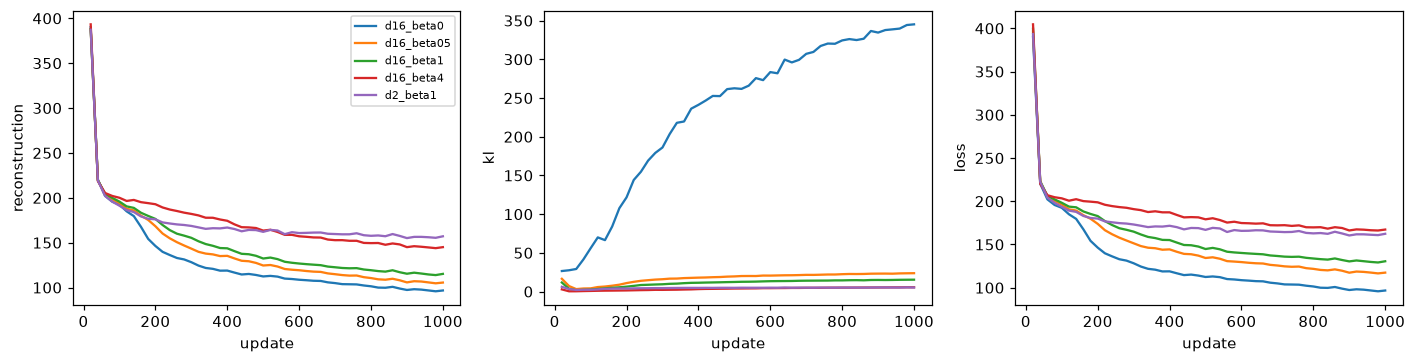

In [32]:
table = "|设置|共同步数|随机重建 BCE/图|均值重建 BCE/图|KL/图|\n|---|---:|---:|---:|---:|\n"
for name, values in comparison.items():
    table += (
        f"|{name}|{common_step}|{values['reconstruction']:.3f}|"
        f"{values['mean_reconstruction']:.3f}|{values['kl']:.3f}|\n"
    )
display(Markdown(table))
fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
for name, run in runs.items():
    rows = run["metrics"]
    for ax, key in zip(axes, ["reconstruction", "kl", "loss"]):
        # Means of blocks of 20 reduce plotting noise, never alter saved raw logs.
        blocks = [rows[i : i + 20] for i in range(0, len(rows), 20)]
        ax.plot(
            [b[-1]["step"] for b in blocks],
            [sum(r[key] for r in b) / len(b) for b in blocks],
            label=name,
        )
        ax.set(xlabel="update", ylabel=key)
axes[0].legend(fontsize=7)
fig.tight_layout()
fig.savefig(FIG / "training_curves.png")
plt.show()

## **九、看见模型究竟学到了什么**

### **1. 全部固定样本：重建与先验生成分别展示**

下面展示验证集前 8 张，不按重建质量筛选。每组三行依次是原图、均值重建、随机重建。先验生成使用同一组固定标准正态坐标，展示全部 16 张概率图；没有人工挑出好看的数字。

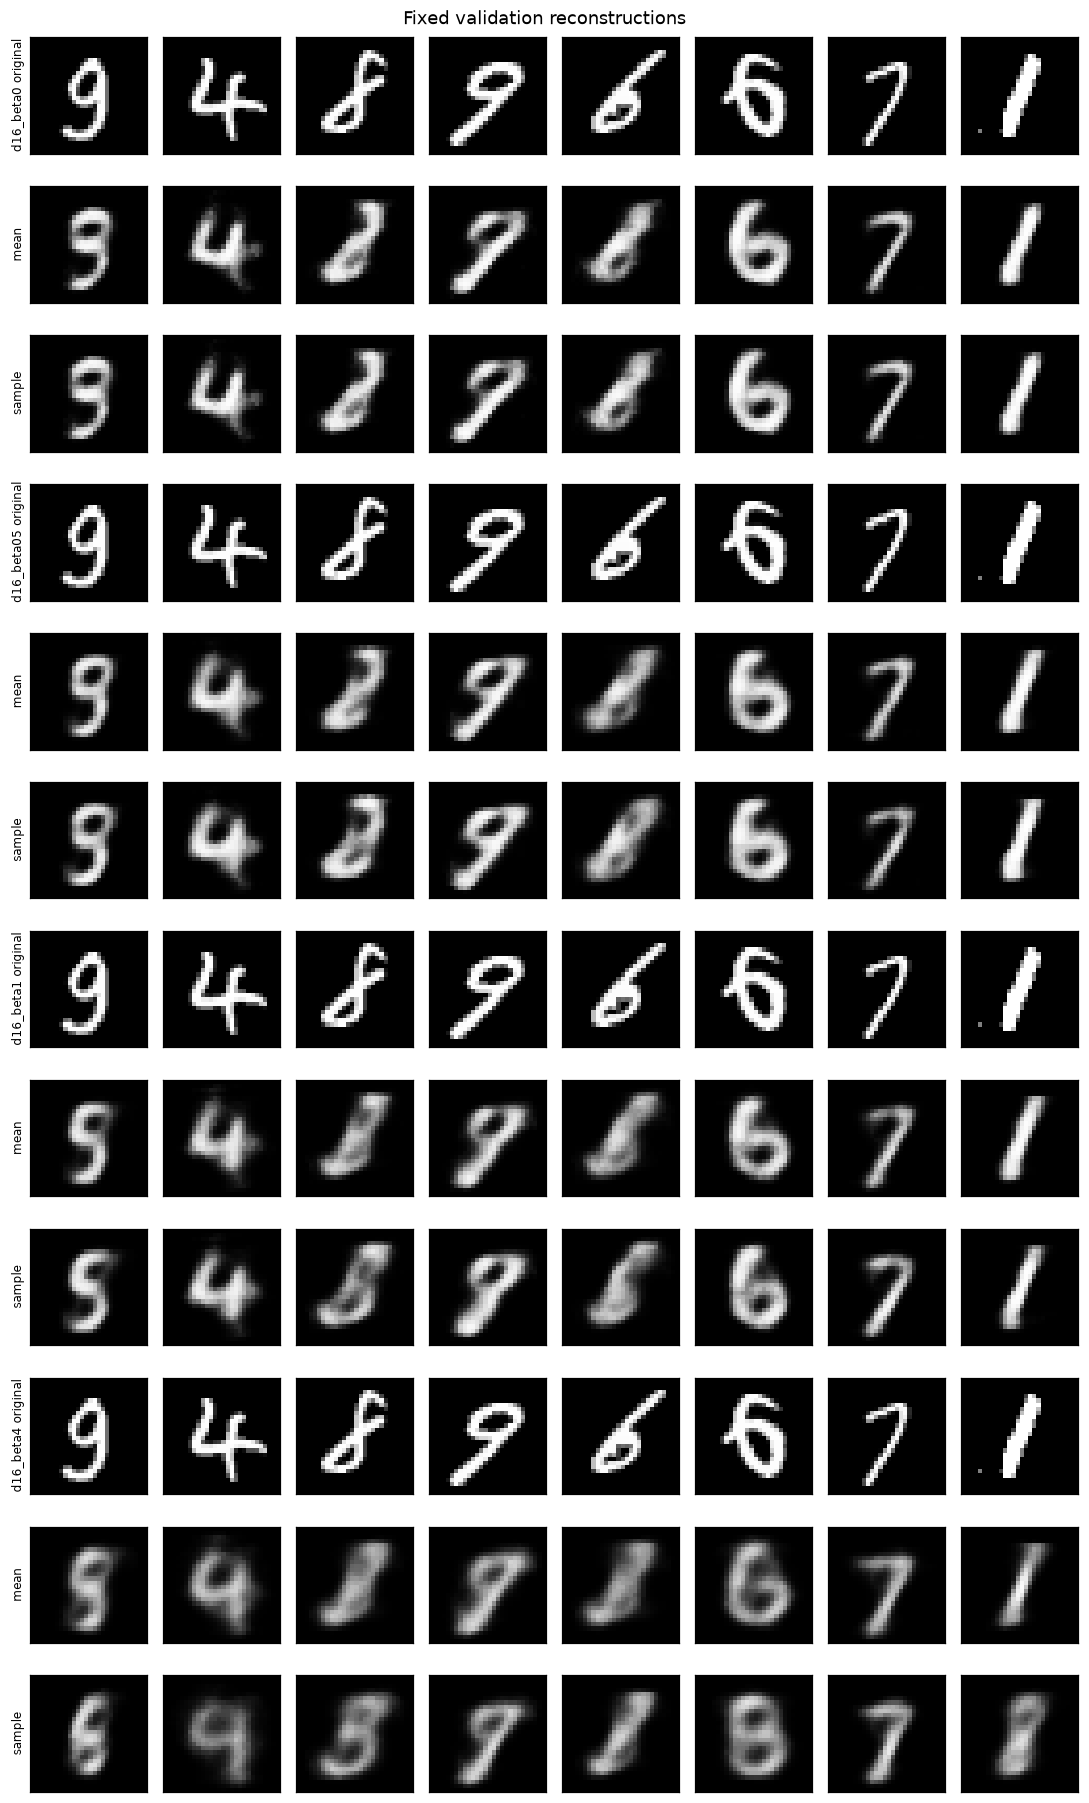

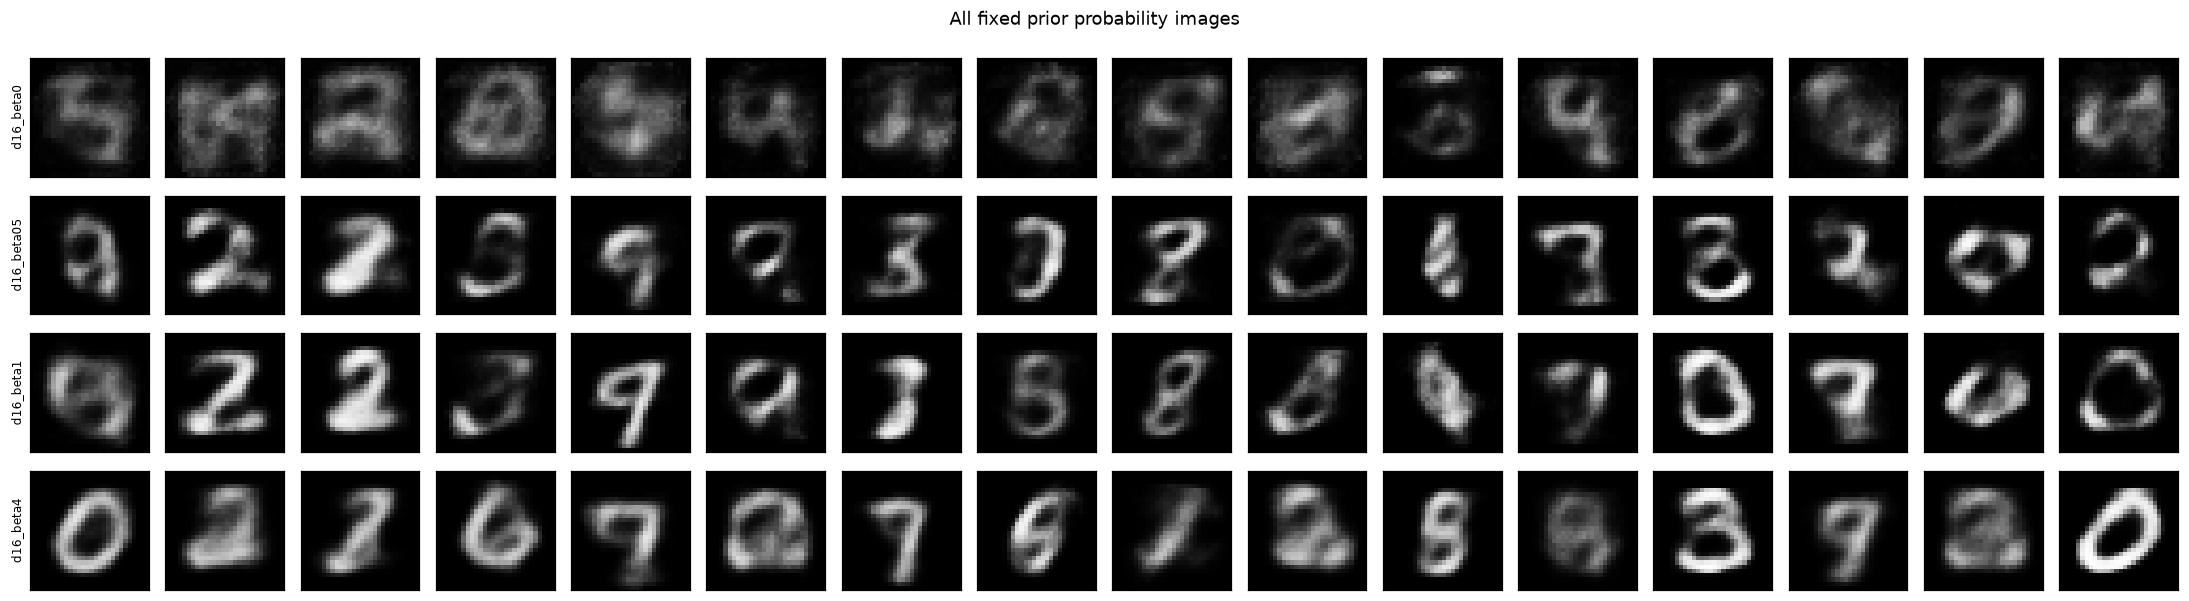

In [33]:
def show_rows(rows, row_names, title, path):
    count = len(rows[0])
    fig, axes = plt.subplots(
        len(rows), count, figsize=(1.25 * count, 1.4 * len(rows)), squeeze=False
    )
    for row, (images, label) in enumerate(zip(rows, row_names)):
        for col, image in enumerate(images):
            axes[row, col].imshow(image.squeeze().cpu(), cmap="gray", vmin=0, vmax=1)
            axes[row, col].set_xticks([])
            axes[row, col].set_yticks([])
        axes[row, 0].set_ylabel(label, fontsize=8)
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(path)
    plt.show()


with torch.no_grad():
    recon_rows, recon_labels = [], []
    generated_rows, generated_labels = [], []
    fixed_prior = torch.randn(16, 16, generator=torch.Generator().manual_seed(2026))
    for name in comparison:
        model = models[name].eval()
        x = val_x[:8].to(DEVICE)
        mean, logvar = model.encode(x)
        noise = torch.randn(8, 16, generator=torch.Generator().manual_seed(2027)).to(DEVICE)
        recon_rows.extend(
            [
                x.cpu(),
                model.decode(mean).sigmoid().cpu(),
                model.decode(teaching_reparameterize(mean, logvar, noise)).sigmoid().cpu(),
            ]
        )
        recon_labels.extend([name + " original", "mean", "sample"])
        generated_rows.append(model.decode(fixed_prior.to(DEVICE)).sigmoid().cpu())
        generated_labels.append(name)
    if recon_rows:
        show_rows(
            recon_rows,
            recon_labels,
            "Fixed validation reconstructions",
            FIG / "reconstructions.png",
        )
        show_rows(
            generated_rows,
            generated_labels,
            "All fixed prior probability images",
            FIG / "prior_samples.png",
        )

### **2. KL 按维拆开，检查“坐标是否被使用”**

若一些维度的 KL、编码均值变化都很小，可能没有携带明显信息；但“KL 小于某个数”不是通用的后验坍塌证明。严重坍塌还应结合解码器是否忽视输入坐标、重建是否几乎固定等证据。

对验证图像的近似聚合分布，其方差可由全方差公式估计：

$$\operatorname{Var}_{q(z)}(z_j)=\operatorname{Var}_x(\mu_j(x))+\mathbb E_x[\exp\ell_j(x)]$$

均值接近零、方差接近一，只检查了一二阶矩，不能证明联合分布是标准正态，更不能证明生成一定好。

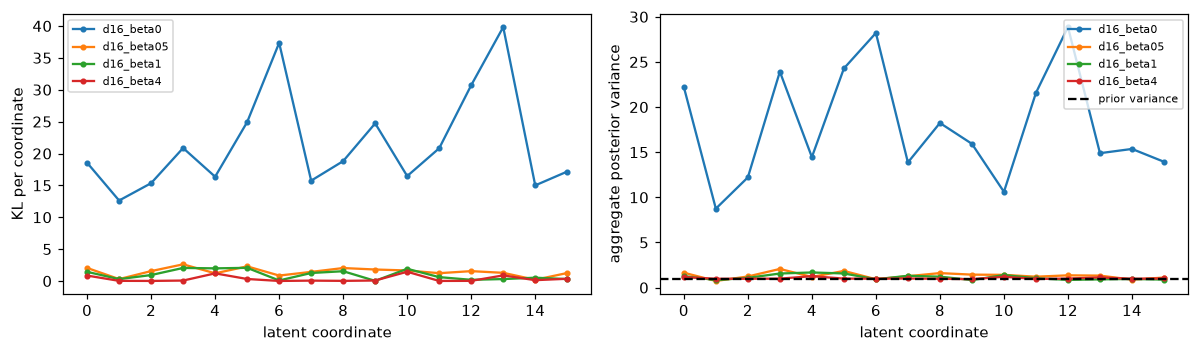

{'d16_beta0': {'mean_abs': 2.807041883468628, 'aggregate_variance_mean': 17.956708908081055}, 'd16_beta05': {'mean_abs': 0.1252603679895401, 'aggregate_variance_mean': 1.3280057907104492}, 'd16_beta1': {'mean_abs': 0.0797707661986351, 'aggregate_variance_mean': 1.1440205574035645}, 'd16_beta4': {'mean_abs': 0.05596232786774635, 'aggregate_variance_mean': 1.0352427959442139}}


In [34]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.3))
for name, values in comparison.items():
    axes[0].plot(values["per_dimension_kl"], marker=".", label=name)
    axes[1].plot(values["aggregate_variance"], marker=".", label=name)
axes[0].set(xlabel="latent coordinate", ylabel="KL per coordinate")
axes[1].axhline(1, color="black", linestyle="--", label="prior variance")
axes[1].set(xlabel="latent coordinate", ylabel="aggregate posterior variance")
for ax in axes:
    ax.legend(fontsize=7)
fig.tight_layout()
fig.savefig(FIG / "latent_statistics.png")
plt.show()
print(
    {
        name: {
            "mean_abs": float(torch.tensor(v["posterior_mean_average"]).abs().mean()),
            "aggregate_variance_mean": float(torch.tensor(v["aggregate_variance"]).mean()),
        }
        for name, v in comparison.items()
    }
)

### **3. 二维潜空间：散点图与解码网格**

散点图使用每张验证图的后验均值，并按真实数字标签上色。标签只用于解释图像，不是训练条件。二维先验网格覆盖标准正态的 5%–95% 分位数；区域相邻且解码平滑，不自动说明语义解耦。

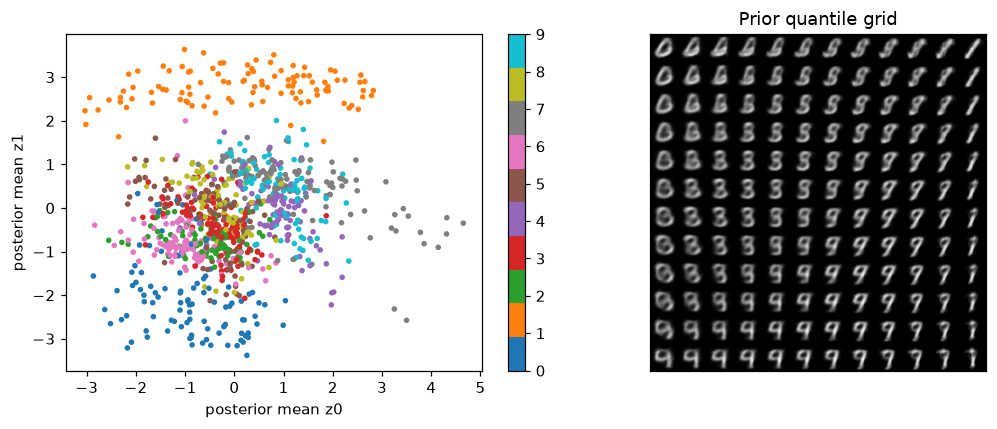

In [45]:
if "d2_beta1" in models:
    model2 = models["d2_beta1"].eval()
    with torch.no_grad():
        means2, _ = model2.encode(val_x.to(DEVICE))
        ticks = torch.distributions.Normal(0, 1).icdf(torch.linspace(0.05, 0.95, 12))
        coords = torch.stack(torch.meshgrid(ticks, ticks, indexing="ij"), -1).reshape(-1, 2)
        tiles = model2.decode(coords.to(DEVICE)).sigmoid().cpu().reshape(12, 12, 28, 28)
        mosaic = tiles.permute(0, 2, 1, 3).reshape(336, 336)
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    dots = axes[0].scatter(means2[:, 0].cpu(), means2[:, 1].cpu(), c=val_labels, cmap="tab10", s=7)
    fig.colorbar(dots, ax=axes[0], ticks=range(10))
    axes[0].set(xlabel="posterior mean z0", ylabel="posterior mean z1")
    axes[1].imshow(mosaic, cmap="gray", vmin=0, vmax=1)
    axes[1].set(title="Prior quantile grid", xticks=[], yticks=[])
    fig.tight_layout()
    fig.savefig(FIG / "two_dimensional_latent.png")
    plt.show()

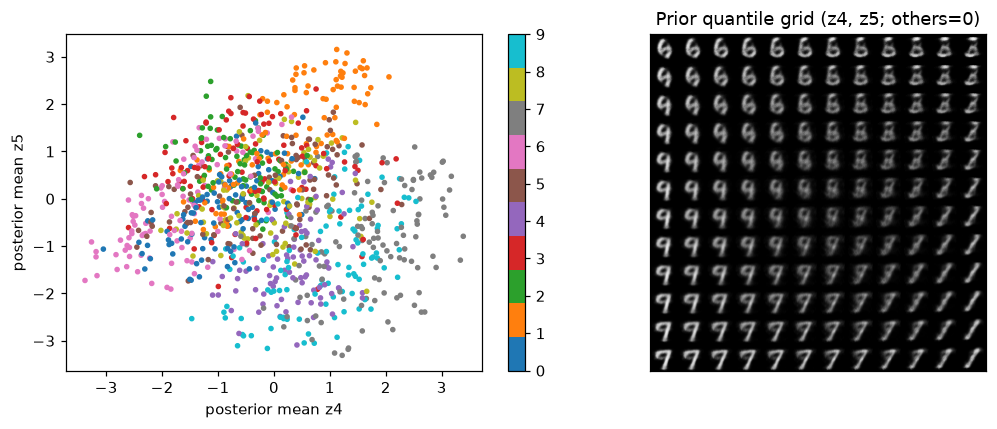

In [54]:
if "d16_beta1" in models:
    model2 = models["d16_beta1"].eval()
    with torch.no_grad():
        means2, _ = model2.encode(val_x.to(DEVICE))   # (N, 16)
        D = means2.shape[1]                            # = 16

        # 选两个要扫的维度。默认取方差最大的两维；也可硬编码 i, j = 0, 1
        i, j = torch.topk(means2.var(dim=0), 2).indices.tolist()
        i, j = sorted((i, j))

        n_grid = 12
        ticks = torch.distributions.Normal(0, 1).icdf(torch.linspace(0.05, 0.95, n_grid))
        grid = torch.stack(torch.meshgrid(ticks, ticks, indexing="ij"), -1).reshape(-1, 2)

        # 16 维坐标：只有 i, j 两维被扫，其余维度固定为 0（先验均值）
        coords = torch.zeros(n_grid * n_grid, D)
        coords[:, i] = grid[:, 0]
        coords[:, j] = grid[:, 1]

        tiles = model2.decode(coords.to(DEVICE)).sigmoid().cpu().reshape(n_grid, n_grid, 28, 28)
        mosaic = tiles.permute(0, 2, 1, 3).reshape(28 * n_grid, 28 * n_grid)

    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    dots = axes[0].scatter(means2[:, i].cpu(), means2[:, j].cpu(),
                           c=val_labels, cmap="tab10", s=7)
    fig.colorbar(dots, ax=axes[0], ticks=range(10))
    axes[0].set(xlabel=f"posterior mean z{i}", ylabel=f"posterior mean z{j}")
    axes[1].imshow(mosaic, cmap="gray", vmin=0, vmax=1)
    axes[1].set(title=f"Prior quantile grid (z{i}, z{j}; others=0)", xticks=[], yticks=[])
    fig.tight_layout()
    fig.savefig(FIG / "two_dimensional_latent.png")
    plt.show()

### **4. 插值与真实失败该怎样记录**

固定验证集第 0、1 张图，线性插值它们的后验均值；它仅展示这两个位置间的路径，不代表整个潜空间都合理，也不表示路径始终位于高概率区域。

观察失败时分别记录：重建缺笔或模糊；先验生成难以辨认；约束增强时内容趋于相似；二维压缩混合不同主体。只把实际出现的现象写进报告。如果没出现后验坍塌，就不能为了“有失败分析”把它强行写成观测结论。

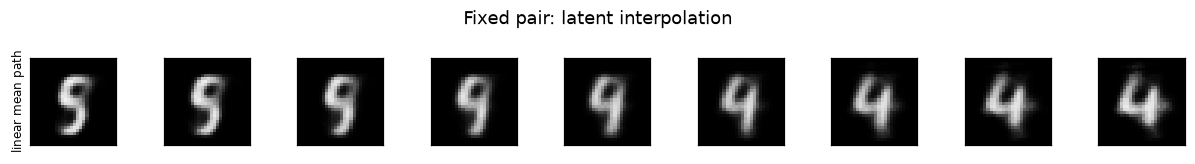

{'fresh_process': True, 'max_abs_logit_difference': 5.7220458984375e-06}


In [60]:
if "d16_beta1" in models:
    with torch.no_grad():
        baseline = models["d16_beta1"].eval()
        endpoints, _ = baseline.encode(val_x[:2].to(DEVICE))
        alpha = torch.linspace(0, 1, 9, device=DEVICE)[:, None]
        path = (1 - alpha) * endpoints[0] + alpha * endpoints[1]
        interpolation = baseline.decode(path).sigmoid().cpu()
    show_rows(
        [interpolation],
        ["linear mean path"],
        "Fixed pair: latent interpolation",
        FIG / "interpolation.png",
    )
    torch.save(
        {
            "latent": fixed_prior,
            "expected_logits": baseline.decode(fixed_prior.to(DEVICE)).detach().cpu(),
        },
        RUN / "reload_probe.pt",
    )
    # Fresh Python process: load decoder and compare deterministic logits on CPU.
    reload_code = """
import json,sys,torch
from pathlib import Path
from minigen.models.tiny_vae import TinyVAE
root=Path(sys.argv[1]); step=int(sys.argv[2])
saved=torch.load(root/'d16_beta1'/f'step_{step:04d}.pt',map_location='cpu',weights_only=True)
probe=torch.load(root/'reload_probe.pt',map_location='cpu',weights_only=True)
model=TinyVAE(16).eval(); model.load_state_dict(saved['model'])
with torch.no_grad(): actual=model.decode(probe['latent'])
error=(actual-probe['expected_logits']).abs().max().item()
torch.testing.assert_close(actual,probe['expected_logits'],rtol=2e-4,atol=2e-4)
print(json.dumps({'fresh_process':True,'max_abs_logit_difference':error}))
"""
    completed = subprocess.run(
        [sys.executable, "-c", reload_code, str(RUN), str(common_step)],
        check=True,
        capture_output=True,
        text=True,
    )
    reload_result = json.loads(completed.stdout)
    print(reload_result)
else:
    reload_result = {"fresh_process": False, "reason": "baseline unavailable"}

本次固定图像的实际观察：不加 KL 时，验证集第 2 列（从 0 编号）的原始数字 8 在均值重建中接近 2；标准权重模型的第 0 张原始 9 重建接近 5，说明重建已出现主体混淆。先验网格中 `beta=0` 行整体更虚、更难辨认，而更强约束的 `beta=4` 行也保留模糊及不规则笔画。二维图中多个数字类别重叠，插值并非清晰的逐步语义控制。这些是目视判断，没有转化为分类准确率。

这些现象支持下一步诊断：分别检查表示容量、重建目标与先验匹配；仅靠本次一组权重对照，不能判定每一张失败样本的唯一原因。本次存在非零 KL 与多样输出，没有据此宣称观察到整体后验坍塌。

## **十、训练恢复：保存参数为什么还不够**

### **1. 需要保存哪几条时间线**

训练状态包括模型、优化器、EMA（去噪器使用时）、更新步数、随机数状态和数据读取位置。只恢复权重会丢失 Adam 动量；只恢复随机种子会从头抽噪声；只保存 epoch 仍可能重复或跳过部分 batch。

本周的 `StatefulBatchStream` 在单进程中保存排列、cursor、epoch 和独立 shuffle generator，并保留最后不足一个 batch 的样本。数据访问必须确定，`num_workers=0`，不处理多 worker 预取或随机数据增强的额外状态。两次训练需要相同设备与环境；跨 CPU/MPS 不要求逐位一致。

下面用 19 个样本、batch 7，比较连续 8 次更新与 3 次后恢复到第 8 次。一次 epoch 是 7、7、5 三个 batch，恰好覆盖短 batch 与跨 epoch。这里仍使用显式教学核心，不涉及未完成的 src 实现。

In [16]:
tiny_data = TensorDataset(train_x[:19])


def tiny_stream():
    return StatefulBatchStream(tiny_data, 7, data_id=DATA_ID + ":resume19", seed=5)


seed_all(99)
initial_model = TinyVAE(2)
resume_validation = val_x[:14]


def resume_train(model, folder, steps, resume=None):
    return train_vae(
        model,
        tiny_stream(),
        VAEConfig(
            str(RUN / folder),
            max_steps=steps,
            beta=1,
            seed=99,
            checkpoint_every=100,
            core_source="notebook_reference",
        ),
        reparameterize_fn=teaching_reparameterize,
        kl_fn=teaching_kl,
        validation=resume_validation,
        resume_path=resume,
    )


continuous = copy.deepcopy(initial_model)
full_run = resume_train(continuous, "resume_full", 8)
partial = resume_train(copy.deepcopy(initial_model), "resume_partial", 3)
resumed = TinyVAE(2)
resumed_run = resume_train(resumed, "resume_restarted", 8, partial["checkpoint"])
max_resume_error = max(
    (a - b).abs().max().item() for a, b in zip(continuous.parameters(), resumed.parameters())
)
assert max_resume_error == 0
assert [r["loss"] for r in full_run["metrics"][3:]] == [r["loss"] for r in resumed_run["metrics"]]
resume_result = {
    "cpu_updates": 8,
    "split_after": 3,
    "max_parameter_error": max_resume_error,
    "subsequent_losses_identical": True,
    "short_batch_size": 5,
}
print(resume_result)

{'cpu_updates': 8, 'split_after': 3, 'max_parameter_error': 0.0, 'subsequent_losses_identical': True, 'short_batch_size': 5}


### **2. 兼容性与验收边界**

数据划分标识、batch 大小、排列和关键训练配置必须兼容；不能因为张量能加载，就认为实验相同。旧去噪 Checkpoint 没有数据读取状态时只能称为普通续训；请求精确恢复时必须明确拒绝。

工程测试还覆盖去噪器的 epoch 中途/跨 epoch 恢复，比较优化器、EMA、后续噪声、损失、数据顺序和随机状态。测试替身只验证工程契约，不作为 DDPM 数学实现或生成成果。

## **十一、连接潜空间扩散，并建立论文阅读地图**

### **1. VAE 与 DDPM 的共同点和不同点**

二者都可以用潜变量模型和变分界理解，但训练和采样结构不同。VAE 主要学习一个编码分布和一个解码分布；DDPM 使用固定前向加噪链与学习的反向链。不要因二者都出现 KL 就把噪声预测 MSE 与 VAE 重建项视为同一种函数。

| 问题 | 本周 VAE | 第一周 DDPM |
| --- | --- | --- |
| 训练输入 | 干净图像 | 干净图像构造的带噪图像与时间 |
| 网络输出 | 分布参数与解码 logits | 噪声预测 |
| 随机性 | 后验潜变量采样 | 时间、加噪、反向采样 |
| 无条件生成 | 先验潜变量一次解码 | 噪声经过完整反向链 |
| 低训练损失的限制 | 不保证先验生成好 | 不保证反向采样好 |

### **2. 为什么下一阶段要先验证 Autoencoder**

潜空间扩散先把图像压成空间潜变量，再在该表示中训练去噪器，最后解码。计算可能减小，但编码阶段已经丢失的小对象、颜色或位置关系，不能期待生成主干稳定补回。

[Latent Diffusion 原论文](https://arxiv.org/abs/2112.10752) 第 3.1–3.2 节及压缩实验用于理解这一取舍。其第一阶段使用重建、感知及正则等设计，不能将本周 BCE+KL 的 MNIST MLP 等同于现代预训练 VAE。下一阶段再检查真实 Autoencoder 的输入范围、潜变量缩放、重建属性保留及缓存版本，本周不下载它的权重。

### **3. 两周论文与阅读卡**

论文来源于 arXiv，版本核验日期 2026-10-24。本节是阅读任务与自己的解释，不复制论文大段原文。PDF、本地哈希和逐篇任务见 [论文目录](../papers/README.md)。

| 论文 | 读哪里 | 读后必须交代 |
| --- | --- | --- |
| [DDPM，2006.11239v2](https://arxiv.org/abs/2006.11239v2) | 第 2–3 节、算法 1/2 | 为什么直接采样可训练，预测噪声怎样决定反向均值 |
| [VAE，1312.6114v11](https://arxiv.org/abs/1312.6114v11) | 第 2–3 节、附录 B/C | 为什么要近似后验、两种 KL 的区别、重参数化的梯度 |
| [LDM，2112.10752v2](https://arxiv.org/abs/2112.10752v2) | 图 1、第 3.1–3.2 节、第 4.1 节 | 表示压缩怎样改变成本与细节，为什么先查重建 |

DDPM 阅读卡：问题是如何稳定训练多步生成；关键连接是变分目标与去噪参数化；对应本项目加噪、损失、反向步；不能从 MNIST 短训推出开放域质量。

VAE 阅读卡：问题是连续潜变量的后验推断与学习；关键改动是近似编码分布及路径梯度；对应两个核心接口与训练目标；不能从 KL 小推出信息一定有用。

LDM 阅读卡：问题是像素空间扩散成本；关键是先学习可重建的压缩表示，再做生成；对应后续冻结 Autoencoder 与 DiT；压缩率和质量的平衡依赖任务，不保证高压缩越好。

## **十二、合上参考：核心练习、诊断与阶段验收**

### **1. 你下一次可以直接开始的任务**

打开 `src/minigen/autoencoders/vae_core.py`，按现有签名完成重参数化与 KL。约定输入 `[B,d]`，噪声显式给定；KL 潜变量维度求和、batch 平均。不要从 Notebook 动态导入答案到 src。

先画输入输出，自己手算 $\mu=1,\sigma^2=4,\epsilon=0.5$，再写两函数；写完运行任务包中的项目核心测试。未完成时测试必须显示待实现，不能默默跳到参考函数。Agent 负责独立审查、工程接入和排错。

第一周 `DDPMScheduler` 仍待你完成；本周教学可以独立继续，但 S1 整阶段不能提前验收。

### **2. 自测题与参考答案**

1. 为什么编码器不是输出一张图的唯一“正确坐标”？

参考：训练没有潜变量标签；编码器拟合给定图像的近似后验。它是一个分布，允许表示不确定性，并通过目标与生成模型共同学习。

2. 哪个 KL 解释下界差距，哪个 KL 出现在可计算损失？

参考：前者是 $q_\phi(z\mid x)$ 对真实后验 $p_\theta(z\mid x)$；后者是对先验 $p(z)$。真实后验一般难算，所以二者用途不能互换。

3. 为什么 `exp(log_variance)` 不能直接乘噪声？

参考：它是方差，采样需要标准差 `exp(0.5*log_variance)`；误用会把采样方差再平方。

4. 为什么不能用 KL 权重 0 的低损失证明它比权重 1 更好？

参考：优化目标变了，约束被移除；必须分别看固定数据上的重建、潜分布和先验生成，且本次单种子不能证明普遍优劣。

5. 均值和方差与先验接近就证明潜空间匹配吗？

参考：一二阶矩不决定一般分布形状或联合依赖，还需观察聚合分布、先验生成及任务相关表现。

6. 为什么只恢复随机种子不能精确续训？

参考：它回到初始随机序列，而不是中断时刻；数据排列、cursor、优化器动量等也有自己的状态。

7. 为什么后续 VAE 重建坏了，应先处理表示而不是增加 DiT 层数？

参考：编码解码链已经破坏任务属性，主干不能稳定恢复不可见信息；应先隔离表示瓶颈，再比较生成能力。

### **3. 本周证据与完成状态**

下面保存真实数值、设备、数据版本、训练上限、停止原因、数学和恢复对照。教学验收可由这些记录支持；个人核心与理解验收保留待做。报告中的目视失败分析另行审核，不由训练 loss 自动推断。

In [17]:
experiment_elapsed = time.monotonic() - experiment_start
results = {
    "date": "2026-10-24",
    "python": sys.version.split()[0],
    "torch": torch.__version__,
    "device": DEVICE,
    "core_source": "notebook_reference",
    "cost_yuan": 0,
    "split_sha256": manifest["split_sha256"],
    "official_test_used": False,
    "math_checks": math_checks,
    "common_step": common_step,
    "fit": {k: v for k, v in fit.items() if k != "metrics"},
    "runs": {
        name: {k: v for k, v in result.items() if k != "metrics"} for name, result in runs.items()
    },
    "comparison": comparison,
    "reload": reload_result,
    "resume": resume_result,
    "experiment_elapsed_seconds": experiment_elapsed,
    "learner_core_verified": False,
    "learner_understanding_verified": False,
    "limitations": [
        "Single training seed",
        "Soft-target BCE is not exact continuous likelihood",
        "No pretrained Autoencoder",
        "No formal generation metric",
        "Test set unused",
    ],
}
(ROOT / "reports/stage1/week2_results.json").write_text(
    json.dumps(results, ensure_ascii=False, indent=2) + "\n"
)
print(
    {
        "elapsed_seconds": round(experiment_elapsed, 2),
        "global_limit_seconds": 1800,
        "results": "reports/stage1/week2_results.json",
        "learner_core": "待做",
        "understanding": "待做",
    }
)
assert experiment_elapsed < 1800, "Local experiment time budget exceeded; inspect actual records"

{'elapsed_seconds': 23.32, 'global_limit_seconds': 1800, 'results': 'reports/stage1/week2_results.json', 'learner_core': '待做', 'understanding': '待做'}
